In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/processed/electric_clean.csv", parse_dates=["Datetime"])
target = df.columns[1]
s = df.set_index("Datetime")[target]

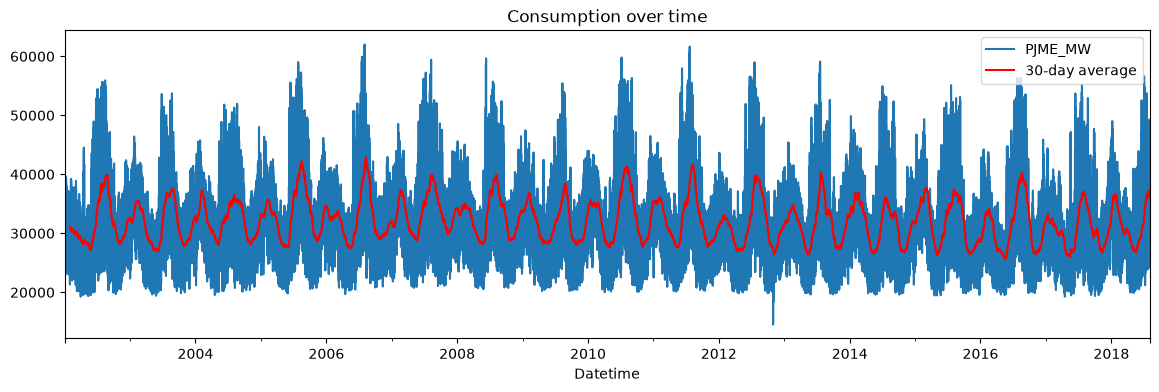

In [2]:
s.plot(figsize=(14, 4), title="Consumption over time")
s.rolling(24 * 30).mean().plot(color="red", label="30-day average")
plt.legend(); plt.show()

<Axes: title={'center': 'Two weeks'}, xlabel='Datetime'>

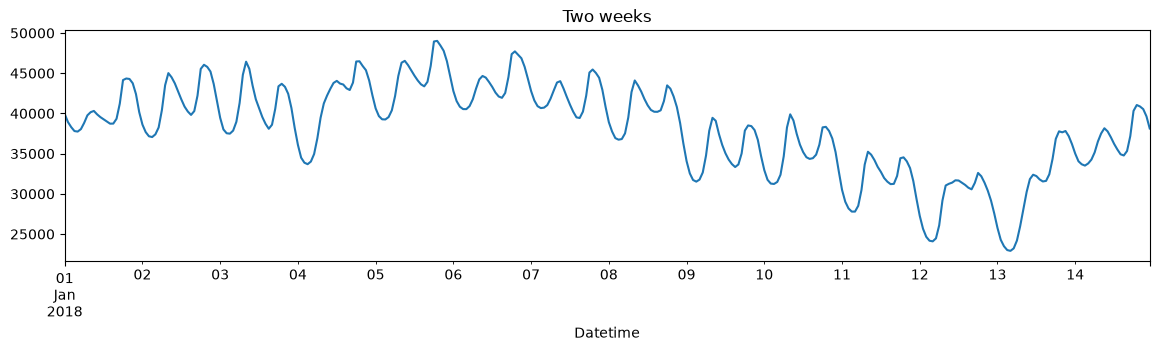

In [3]:
s["2018-01-01":"2018-01-14"].plot(figsize=(14, 3), title="Two weeks")

/tmp/ipykernel_10712/762007304.py:3: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  d["DayOfWeek"] = d["Datetime"].dt.dayofweek


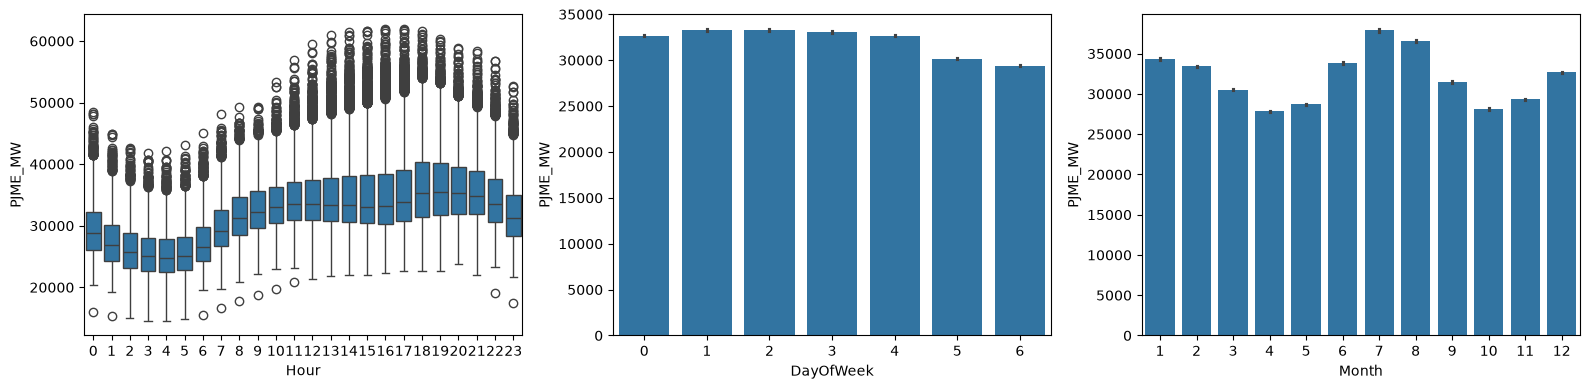

In [4]:
d = df.copy()
d["Hour"] = d["Datetime"].dt.hour
d["DayOfWeek"] = d["Datetime"].dt.dayofweek
d["Month"] = d["Datetime"].dt.month

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.boxplot(data=d, x="Hour", y=target, ax=ax[0])
sns.barplot(data=d, x="DayOfWeek", y=target, ax=ax[1])
sns.barplot(data=d, x="Month", y=target, ax=ax[2])
plt.tight_layout(); plt.show()

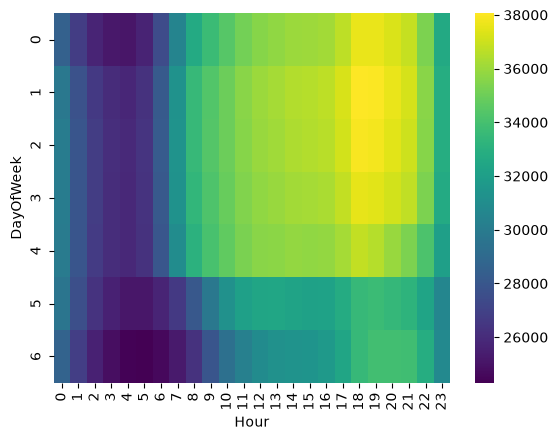

In [5]:
pivot = d.pivot_table(index="DayOfWeek", columns="Hour", values=target, aggfunc="mean")
sns.heatmap(pivot, cmap="viridis"); plt.show()

### seasonality and autocorrelation

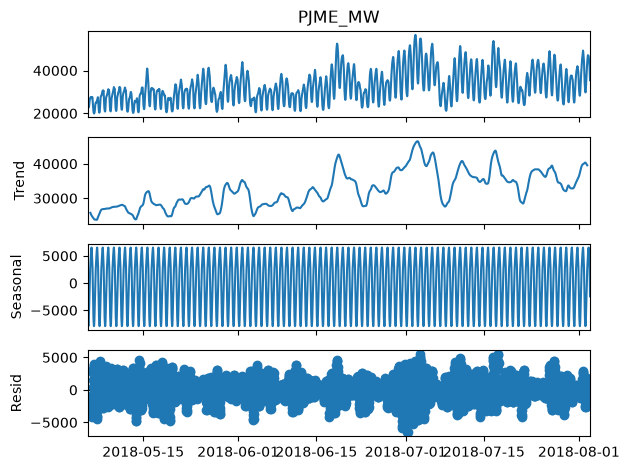

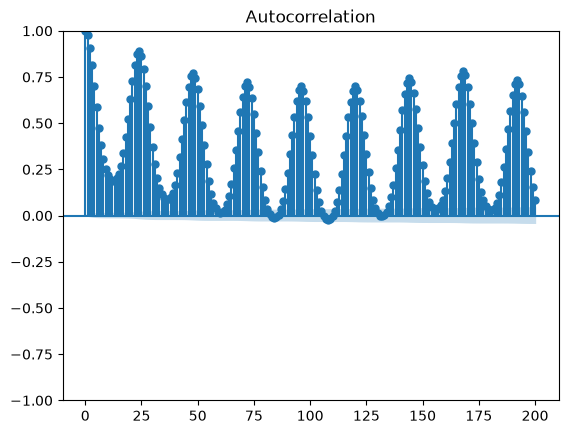

In [6]:
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf

# last 90 days only
seasonal_decompose(s.iloc[-24 *  90:], model="additive", period=24).plot()
plt.show()

plot_acf(s, lags=200)
plt.show()

### yearly trend

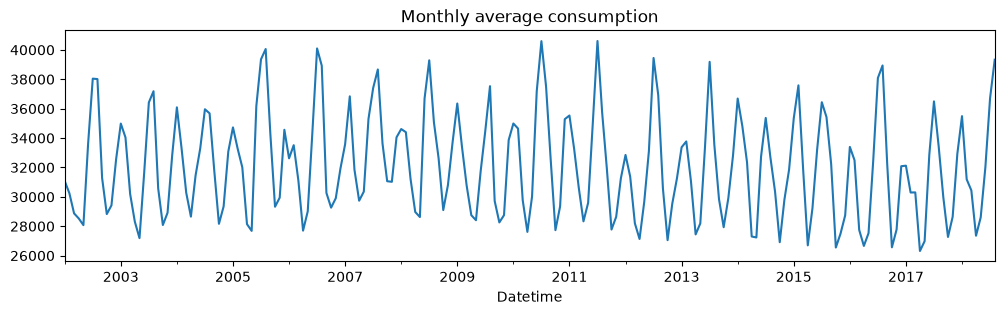

In [7]:
s.resample("MS").mean().plot(figsize=(12, 3), title="Monthly average consumption")
plt.show()